<a href="https://colab.research.google.com/github/okuchap/GB656_2026_public/blob/main/module8/GB656_08_WineExample.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting High Quality Wines

In this example, we consider a **classification problem** where we classify red wines into high-quality wines (1) and low-quality wines (0). The features are physicochemical measurements of the wines. The original quality scores come from sensory evaluations by wine experts. In the supplied dataset, quality is already recoded as a binary target: 1 for an original score of at least 7, and 0 otherwise. The data originate from the [UCI Wine Quality dataset](https://archive.ics.uci.edu/dataset/186/wine%2Bquality).

## Business Setting

Here is an example of a hypothetical business setting where this predictive problem would be relevant:

"I work on a team for the Castco retail company. We offer wine to our customers, although our selection is relatively small in comparison to wine speciality shops. We do order and sell large quantities of most of our wines though. Therefore, it is important to our business that the wines we select for our offerings are high quality. In the past, we used user groups to assess quality, but scheduling user groups is costly and the timeline of our purchasing process often does not allow for setting up a representative group. My team has been tasked to use analytics to discern likely high-quality wines from our past experience based on chemical characteristics of the wines. It is easier to obtain the chemical specifications from a lab, and our model will provide immediate predictions of whether a given wine is likely high-quality. This is important information (in addition to price and other attributes) for our purchasers."

As an aside, this setting is informed by a story about the [wine purchaser of the retailer Costco](https://www.businessinsider.com/annette-alvarez-peters-powerful-wine-merchant-costco-employee-2012-4#:~:text=Her%20name%20is%20Annette%20Alvarez,dollars%20worth%20of%20wine%20annually.) :-). Apparently she is "the world's most powerful person in wine."

## Exploring the Data

We start by loading and exploring the data. The exploration is going to be key in informing our modeling process.

### Loading Data

Let's load relevant packages and the data:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Course data are loaded directly from the 2026 public repository below.
# You do not need to clone a repository or upload data in Colab.

In [3]:
wine_dat = pd.read_csv('https://raw.githubusercontent.com/okuchap/GB656_2026_public/main/module8/GB656_08_winequality.csv')

### Reserve the Test Set

Some rows contain identical measurements and quality labels. We keep one copy of each exact row so identical records cannot appear on both sides of the split. The evaluation then describes distinct observed chemistry profiles.

We randomly set aside 25% of these profiles for final testing, with a fixed seed for reproducibility. The remaining 75% are the development data for exploration, feature choices, fitting, and tuning.

In [4]:
from sklearn.model_selection import train_test_split

In [5]:
wine_dat = wine_dat.drop_duplicates()
train_data, test_data = train_test_split(wine_dat, test_size=0.25, random_state=42)

In [6]:
train_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
177,7.5,0.52,0.42,2.3,0.087,8.0,38.0,0.99720,3.58,0.61,10.5,0
1366,7.3,0.74,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,0
617,11.5,0.31,0.51,2.2,0.079,14.0,28.0,0.99820,3.03,0.93,9.8,0
814,12.6,0.41,0.54,2.8,0.103,19.0,41.0,0.99939,3.21,0.76,11.3,0
1170,9.2,0.36,0.34,1.6,0.062,5.0,12.0,0.99667,3.20,0.67,10.5,0


The development data have 11 numeric features and `quality` as the target.

### Data Exploration

Let's look at correlations between the features and quality in the development data:

In [7]:
corr = train_data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap=sns.diverging_palette(10, 250, as_cmap=True), vmin=-1, vmax=1, annot=True)

<Axes: >

The heatmap shows pairwise linear associations. Let's look more closely at how the average quality label changes across values of each feature. The plots use `sns.regplot` to bin the feature values.

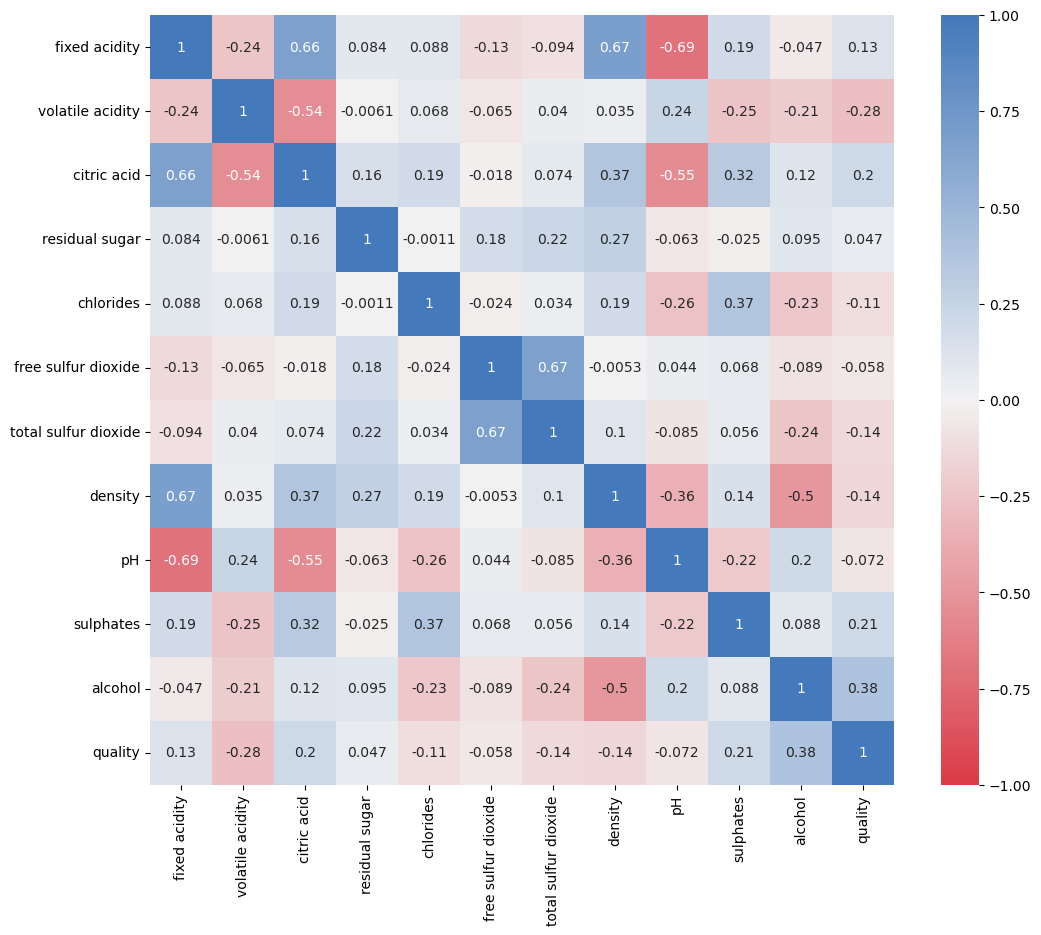

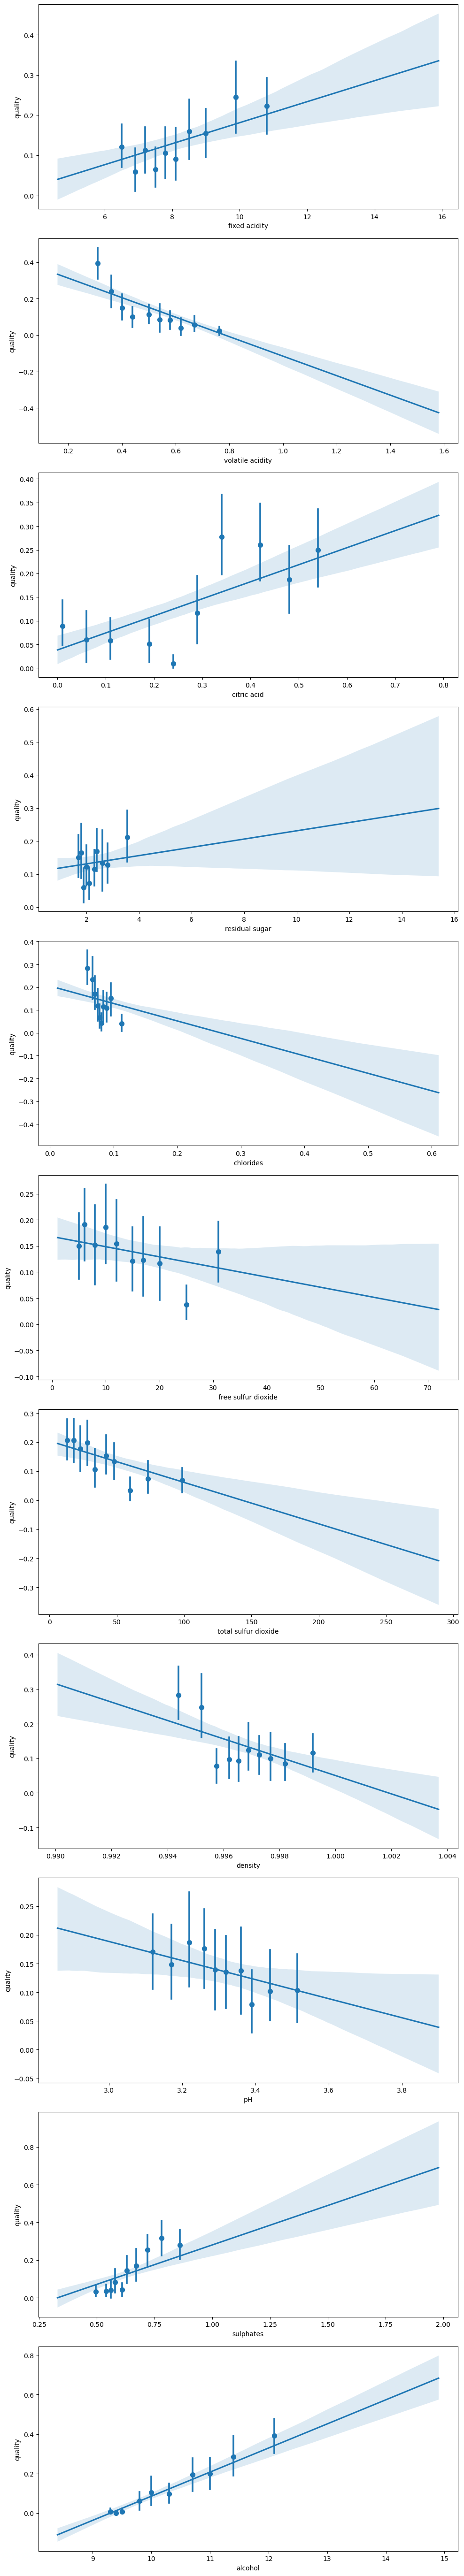

In [8]:
features = train_data.columns.drop('quality')
fig, axes = plt.subplots(len(features), 1, figsize=(10, 5 * len(features)))
for i, feature in enumerate(features):
    sns.regplot(x=feature, y='quality', data=train_data, x_bins=10, ax=axes[i])
plt.tight_layout()
plt.show()

Several features may have nonlinear relationships with the quality label. We will try some higher-order terms. First, let's look at sulphates and alcohol together in a labeled scatter plot:

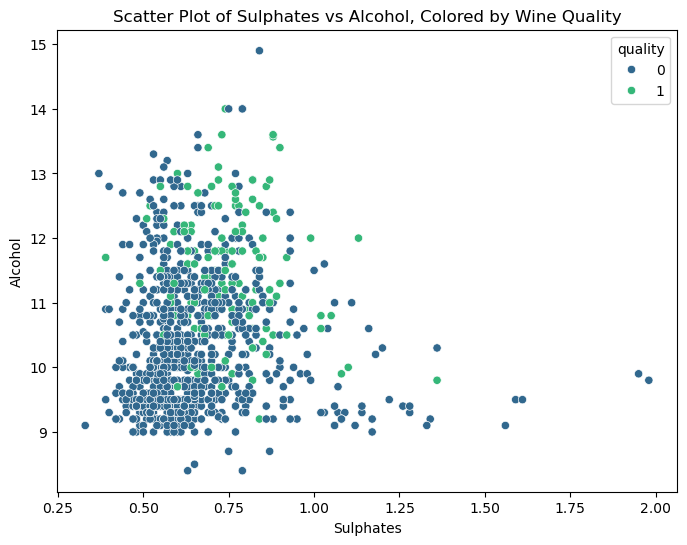

In [9]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='sulphates', y='alcohol', hue='quality', data=train_data, palette='viridis')
plt.xlabel('Sulphates')
plt.ylabel('Alcohol')
plt.title('Scatter Plot of Sulphates vs Alcohol, Colored by Wine Quality')
plt.show()


The plot suggests exploring whether alcohol and sulphates jointly predict the quality label. We will include an alcohol–sulphates interaction and an interaction with squared sulphates, along with a few other powers. Each feature is calculated from the measurements for a single wine.

In [10]:
def add_features(data):
    data = data.copy()
    data['volatile acidity squared'] = data['volatile acidity'] ** 2
    data['sulphates squared'] = data['sulphates'] ** 2
    data['sulphates cubed'] = data['sulphates'] ** 3
    data['chlorides squared'] = data['chlorides'] ** 2
    data['density squared'] = data['density'] ** 2
    data['citric acid squared'] = data['citric acid'] ** 2
    data['alcohol x sulphates'] = data['alcohol'] * data['sulphates']
    data['alcohol x sulphates squared'] = data['alcohol'] * data['sulphates'] ** 2
    return data

train_data = add_features(train_data)

Here is a look at our updated data:

In [11]:
train_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,volatile acidity squared,sulphates squared,sulphates cubed,chlorides squared,density squared,citric acid squared,alcohol x sulphates,alcohol x sulphates squared
177,7.5,0.52,0.42,2.3,0.087,8.0,38.0,0.99720,3.58,0.61,10.5,0,0.2704,0.3721,0.226981,0.007569,0.994408,0.1764,6.405,3.90705
1366,7.3,0.74,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,0,0.5476,0.2500,0.125000,0.008836,0.991538,0.0064,4.900,2.45000
617,11.5,0.31,0.51,2.2,0.079,14.0,28.0,0.99820,3.03,0.93,9.8,0,0.0961,0.8649,0.804357,0.006241,0.996403,0.2601,9.114,8.47602
814,12.6,0.41,0.54,2.8,0.103,19.0,41.0,0.99939,3.21,0.76,11.3,0,0.1681,0.5776,0.438976,0.010609,0.998780,0.2916,8.588,6.52688
1170,9.2,0.36,0.34,1.6,0.062,5.0,12.0,0.99667,3.20,0.67,10.5,0,0.1296,0.4489,0.300763,0.003844,0.993351,0.1156,7.035,4.71345


We could do even more exploring here---for instance, we could look at other interactions. So, think about this example not as exhaustive but more as suggestive. I hope you will spend some more time and thoughts than I did on your project.

## First Model: Logistic Regression with All Features

We start with unpenalized logistic regression using the original and engineered features. Scaling helps the solver fit this model with features measured in very different units.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [13]:
X_train = train_data.drop(columns='quality')
y_train = train_data['quality']

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty=None, max_iter=30000),
)
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=30000, penalty=None))])

## Second Model: Logistic LASSO

Logistic LASSO uses the same features but can shrink some coefficients to zero. We choose the penalty using five-fold cross-validation on the development data. We fit the scaler inside each fold so its means and standard deviations come from that fold's training rows.

In [14]:
from sklearn.model_selection import GridSearchCV, KFold

In [15]:
l1_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(penalty='l1', solver='liblinear', max_iter=30000, random_state=42),
)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [16]:
search = GridSearchCV(
    l1_pipeline,
    {'logisticregression__C': np.logspace(-4, 4, 10)},
    scoring='accuracy',
    cv=cv,
)
search.fit(X_train, y_train)
model_l1 = search.best_estimator_

print("Best C:", search.best_params_['logisticregression__C'])
print("Coefficients:", model_l1.named_steps['logisticregression'].coef_)

Best C: 2.782559402207126
Coefficients: [[ 0.48795551 -0.65867194 -0.6737547   0.27804102 -0.76051169  0.01480686
  -0.39065931 -0.12994722 -0.15302992  0.8372238   0.28332808  0.
   0.         -1.33068042  0.42187761 -0.34654069  0.47431931  0.92627553
   0.        ]]


In [17]:
coefficients = model_l1.named_steps['logisticregression'].coef_[0]
zero_coef_features = X_train.columns[coefficients == 0]
print("Features with zero coefficients:", zero_coef_features.tolist())

Features with zero coefficients: ['volatile acidity squared', 'sulphates squared', 'alcohol x sulphates squared']


## Compare the Models on the Held-Out Test Set

Both models are now fixed. Apply the same feature formulas to the held-out wines, then evaluate both models on those wines. We use a 0.50 cutoff for both confusion matrices.

In [18]:
X_test = add_features(test_data).drop(columns='quality')
y_test = test_data['quality']
y_pred = model.predict(X_test)

conf_matrix = confusion_matrix(y_test, y_pred)

print(conf_matrix)  # Rows: actual labels; columns: predicted labels. [[TN, FP], [FN, TP]]

misclassification_rate = (conf_matrix[0, 1] + conf_matrix[1, 0]) / np.sum(conf_matrix)
fp_rate = conf_matrix[0, 1] / (conf_matrix[0, 0] + conf_matrix[0, 1])
fn_rate = conf_matrix[1, 0] / (conf_matrix[1, 0] + conf_matrix[1, 1])

print(f"Misclassification Rate: {misclassification_rate:.4f}")
print(f"False Positive Rate: {fp_rate:.4f}")
print(f"False Negative Rate: {fn_rate:.4f}")

[[284  12]
 [ 24  20]]
Misclassification Rate: 0.1059
False Positive Rate: 0.0405
False Negative Rate: 0.5455


Let's also look at the ROC curve, and the associated AUC, in the test set:

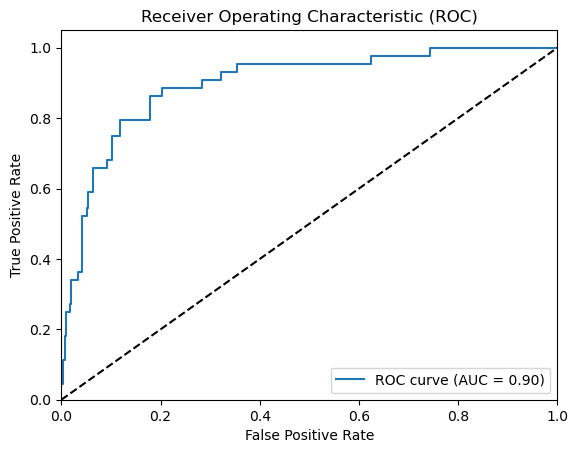

In [19]:
y_pred_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba) # Calculate ROC curve
auc = roc_auc_score(y_test, y_pred_proba) # Calculate AUC

plt.figure() # Plot ROC curve
plt.plot(fpr, tpr, label='ROC curve (AUC = {:.2f})'.format(auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

Now apply the same cutoff to the LASSO model on the same held-out wines:

In [20]:
y_pred_l1 = model_l1.predict(X_test)
conf_matrix_l1 = confusion_matrix(y_test, y_pred_l1)
print("Confusion Matrix (L1):\n", conf_matrix_l1)

misclassification_rate_l1 = (conf_matrix_l1[0, 1] + conf_matrix_l1[1, 0]) / np.sum(conf_matrix_l1)
fp_rate_l1 = conf_matrix_l1[0, 1] / (conf_matrix_l1[0, 0] + conf_matrix_l1[0, 1])
fn_rate_l1 = conf_matrix_l1[1, 0] / (conf_matrix_l1[1, 0] + conf_matrix_l1[1, 1])

print(f"Misclassification Rate: {misclassification_rate_l1:.4f}")
print(f"False Positive Rate: {fp_rate_l1:.4f}")
print(f"False Negative Rate: {fn_rate_l1:.4f}")

Confusion Matrix (L1):
 [[286  10]
 [ 27  17]]
Misclassification Rate: 0.1088
False Positive Rate: 0.0338
False Negative Rate: 0.6136


We can also look at how well LASSO ranks high-quality wines across thresholds using the ROC curve and AUC:

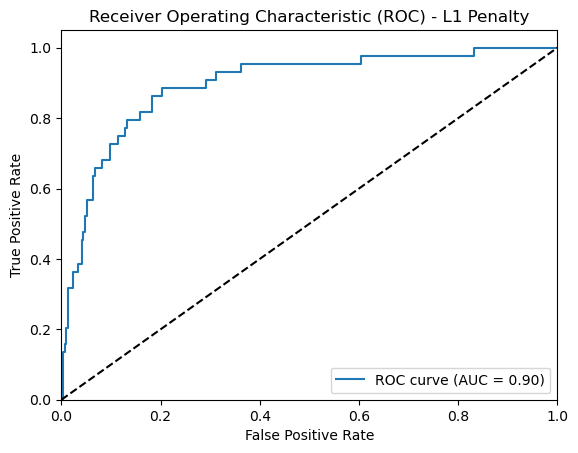

In [21]:
# ROC and AUC
y_pred_proba_l1 = model_l1.predict_proba(X_test)[:, 1]
fpr_l1, tpr_l1, _ = roc_curve(y_test, y_pred_proba_l1)
auc_l1 = roc_auc_score(y_test, y_pred_proba_l1)

# Plot ROC curve
plt.figure()
plt.plot(fpr_l1, tpr_l1, label='ROC curve (AUC = {:.2f})'.format(auc_l1))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - L1 Penalty')
plt.legend(loc="lower right")
plt.show()

Compare the two models' error rates and AUCs on this split. A false positive sends an ordinary wine for follow-up. A false negative misses a high-quality candidate. The two errors can matter differently to a buyer even when the models have similar overall accuracy.

## Optional: Refit for Future Predictions

After recording the held-out results, we can fit the selected LASSO pipeline on all the distinct profiles to use it for new wines. The penalty and feature formulas stay fixed. The held-out results above describe the models fitted before this optional step.

In [22]:
from sklearn.base import clone

X_all = add_features(wine_dat).drop(columns='quality')
model_lasso_full = clone(model_l1)
model_lasso_full.fit(X_all, wine_dat['quality'])

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=np.float64(2.782559402207126),
                                    max_iter=30000, penalty='l1',
                                    random_state=42, solver='liblinear'))])

For the 2026 final project, submit your report PDF and reproducible code through Canvas.